# phase A — FER2013 experiments

In this notebook I compare three ways of describing a face (HOG, landmarks and PCA) and three classifiers (Logistic Regression, SVM and Random Forest). I then try two small changes to see if the best model improves.

I use the **training set** to fit models and the **validation set** to compare them. I leave the **test set** untouched until the final check. The results below must come from running the cells; no scores have been added in advance.

## 1. Imports and settings

Run this notebook from the root of the GitHub project, where the `src` folder is located. If a library is missing, install the dependencies from `requirements_phase_a.txt`.

In [3]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from features import EMOTIONS, fer_images, hog_features, landmark_features, evaluate


DATA_DIR = Path('../data/fer')
OUT_DIR = Path('../results/phase_a')
MODELS_DIR = Path('../models/phase_a')
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Smaller samples are useful for a first check. Use 0 for all images.
MAX_TRAIN = 1000
MAX_VALIDATION = 300


## 2. Load the FER2013 data

Each row contains an emotion label and a string of pixel values. I take roughly the same proportion from every class when using a small sample. First download the dataset using kagglehub and create the csvs.

In [4]:
# import kagglehub

#Download the dataset from Kaggle and extract it to the data directory
# path = kagglehub.dataset_download("purnisharma/fer2013")
# from pathlib import Path

# dataset_path = Path(
#     r"C:\Users\LENOVO\.cache\kagglehub\datasets\purnisharma\fer2013\versions\1"
# )

# for file in dataset_path.rglob("*"):
#     if file.is_file():
#         print(file.relative_to(dataset_path))
# print("Path to dataset files:", path)

from pathlib import Path

dataset_path = Path(
    r"C:\Users\LENOVO\.cache\kagglehub\datasets\purnisharma\fer2013\versions\1"
)

df = pd.read_csv(dataset_path / "fer2013.csv")

print(df.shape)
print(df.columns.tolist())
print(df.head())

from pathlib import Path

# Use the original FER2013 splits
train = df[df["Usage"] == "Training"][["emotion", "pixels"]].copy()
val = df[df["Usage"] == "PublicTest"][["emotion", "pixels"]].copy()
test = df[df["Usage"] == "PrivateTest"][["emotion", "pixels"]].copy()

# Save them in our project
output_dir = Path(r"C:\Users\LENOVO\Emotion_Recognition\data\fer")
output_dir.mkdir(parents=True, exist_ok=True)

train.to_csv(output_dir / "fer2013_train.csv", index=False)
val.to_csv(output_dir / "fer2013_validation.csv", index=False)
test.to_csv(output_dir / "fer2013_test.csv", index=False)

print("Training:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

(35887, 3)
['emotion', 'pixels', 'Usage']
   emotion                                             pixels     Usage
0        0  70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...  Training
1        0  151 150 147 155 148 133 111 140 170 174 182 15...  Training
2        2  231 212 156 164 174 138 161 173 182 200 106 38...  Training
3        4  24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...  Training
4        6  4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...  Training
Training: 28709
Validation: 3589
Test: 3589


Split the dataset in training and validation set.

In [5]:
def load_split(path, max_rows, seed=42):
    df = pd.read_csv(path)
    if 'emotion' not in df.columns or 'pixels' not in df.columns:
        raise ValueError(f'{path}: expected emotion and pixels columns')
    if max_rows and len(df) > max_rows:
        # Keep class proportions close to the original distribution.
        df = df.groupby('emotion', group_keys=False).sample(
            frac=max_rows / len(df), random_state=seed)
    return df.reset_index(drop=True)
print(DATA_DIR / 'fer2013_train.csv')
train = load_split(DATA_DIR / 'fer2013_train.csv', MAX_TRAIN)

val = load_split(DATA_DIR / 'fer2013_validation.csv', MAX_VALIDATION)
print('Training images:', len(train))
print('Validation images:', len(val))
train.head()

..\data\fer\fer2013_train.csv
Training images: 999
Validation images: 301


,emotion,pixels
0,0,133 103 77 54 28 30 34 30 31 51 75 53 35 32 45...
1,0,24 18 27 33 26 23 25 45 63 93 85 62 86 101 116...
2,0,228 221 215 212 215 223 242 245 244 247 249 24...
3,0,222 227 203 90 86 90 84 77 94 87 99 119 134 14...
4,0,75 101 96 44 49 70 77 88 92 87 82 75 72 62 52 ...


Test facial landmarks are loaded correclty

In [6]:
images = fer_images(train.iloc[:1])
landmarks = landmark_features(images)

print("Landmark shape:", landmarks.shape)

Landmark shape: (1, 136)


## 3. Look at the images

First I check how many examples we have for each emotion. This matters because a model can look accurate while doing badly on rare emotions.

In [7]:
def explore(df, out_dir):
    counts = df.emotion.value_counts().reindex(range(7), fill_value=0)
    counts.index = EMOTIONS
    counts.rename_axis('emotion').to_csv(out_dir / 'class_counts.csv', header=['count'])
    fig, ax = plt.subplots(figsize=(8, 4))
    counts.plot.bar(ax=ax)
    ax.set_ylabel('Number of images')
    ax.set_title('FER2013 class distribution (training data)')
    fig.tight_layout()
    fig.savefig(out_dir / 'class_distribution.png', dpi=150)
    plt.close(fig)
    ims = fer_images(df)
    means, stds = ims.mean(axis=(1, 2)), ims.std(axis=(1, 2))
    pd.DataFrame({'brightness': means, 'contrast': stds}).describe().to_csv(out_dir / 'image_statistics.csv')
    fig, axes = plt.subplots(1, 7, figsize=(14, 2.5))
    for label, ax in enumerate(axes):
        pos = np.flatnonzero(df.emotion.to_numpy() == label)
        if len(pos): ax.imshow(ims[pos[0]], cmap='gray', vmin=0, vmax=255)
        ax.set_title(EMOTIONS[label]); ax.axis('off')
    fig.tight_layout()
    fig.savefig(out_dir / 'sample_images.png', dpi=150)
    plt.close(fig)


explore(train, OUT_DIR)
train.emotion.map(dict(enumerate(EMOTIONS))).value_counts()


emotion
Happy       251
Neutral     173
Sad         168
Fear        143
Angry       139
Surprise    110
Disgust      15
Name: count, dtype: int64

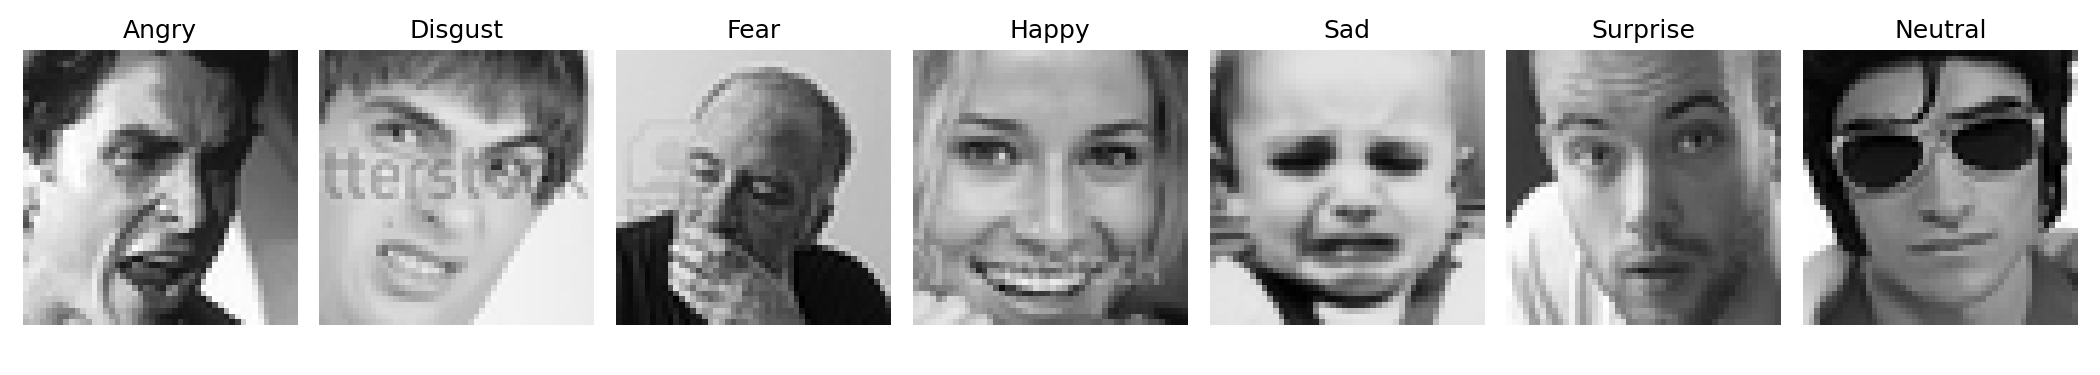

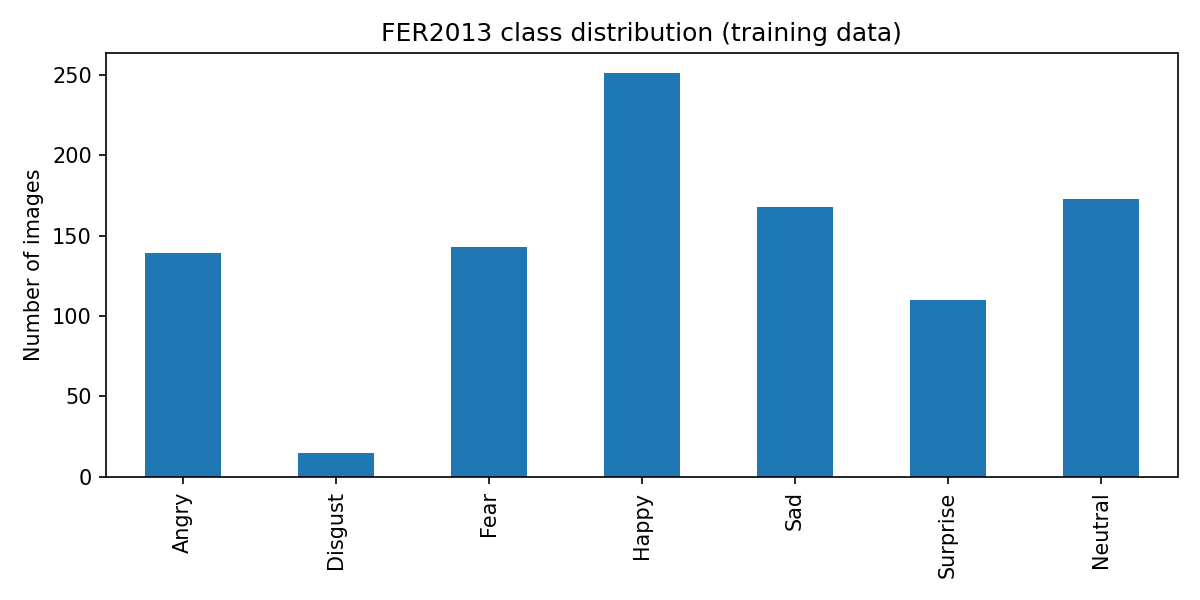

In [8]:
from IPython.display import display, Image
display(Image(filename=str(OUT_DIR / 'sample_images.png')))
display(Image(filename=str(OUT_DIR / 'class_distribution.png')))


## 4. Feature extraction

- **HOG** captures edges and changes in shape.
- **Landmarks** use 68 points around the eyes, mouth, nose and jaw.
- **PCA** reduces the number of pixel values while keeping the main patterns.

PCA is fitted on the training images only, so the validation data does not influence the extracted components.

In [9]:
def features_for(name, train_imgs, val_imgs, test_imgs, model_dir, include_test=False):
    if name == 'PCA':
        transformer = make_pipeline(StandardScaler(), PCA(n_components=min(100, len(train_imgs) - 1, train_imgs.shape[1] * train_imgs.shape[2]), svd_solver='randomized', random_state=42))
        # Use 100 components for speed; PCA is fitted only to training data.
        x_train = transformer.fit_transform(train_imgs.reshape(len(train_imgs), -1))
        x_val = transformer.transform(val_imgs.reshape(len(val_imgs), -1))
        x_test = transformer.transform(test_imgs.reshape(len(test_imgs), -1)) if include_test else None
        return x_train, x_val, x_test, transformer
    if name == 'HOG': func = hog_features
    else: func = landmark_features
    return func(train_imgs), func(val_imgs), func(test_imgs) if include_test else None, None


y_train = train.emotion.to_numpy()
y_val = val.emotion.to_numpy()
train_imgs = fer_images(train)
val_imgs = fer_images(val)


## 5. Define the classifiers

I use Logistic Regression, an RBF SVM and a Random Forest. Scaling is included for Logistic Regression and SVM because their results depend on feature magnitude.

In [10]:
def make_model(kind, class_weight=None, c=1.0):
    if kind == 'LR':
        return make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=2000,
                                    class_weight=class_weight, random_state=42))
    if kind == 'SVM':
        return make_pipeline(StandardScaler(), SVC(C=c, kernel='rbf', gamma='scale',
                                    class_weight=class_weight, cache_size=500))
    return RandomForestClassifier(n_estimators=150, max_depth=None,
                                  class_weight=class_weight, random_state=42, n_jobs=-1)


## 6. Train the nine baseline combinations

The same validation data is used for every combination. I compare **accuracy**, **balanced accuracy** and **macro F1**, with macro F1 useful when some emotions have fewer examples. Landmark extraction may take a while.

dlib version: 19.24.2
Current directory: c:\Users\LENOVO\Emotion_Recognition\src
Landmark shape: (1, 136)
Extracting: HOG
Training: HOG_LR


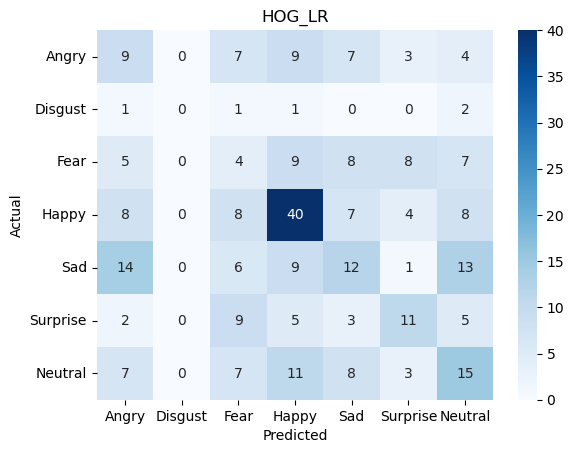

Training: HOG_SVM


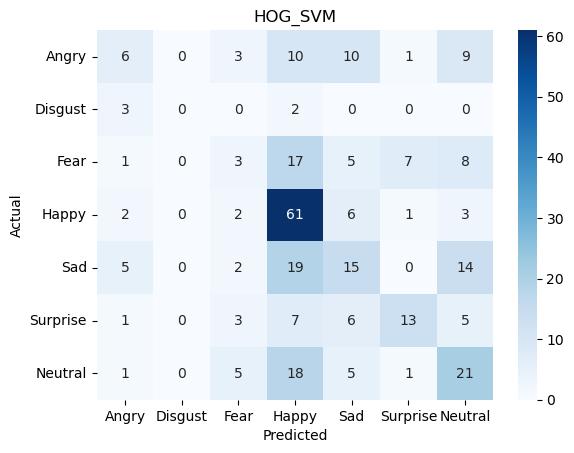

Training: HOG_RF


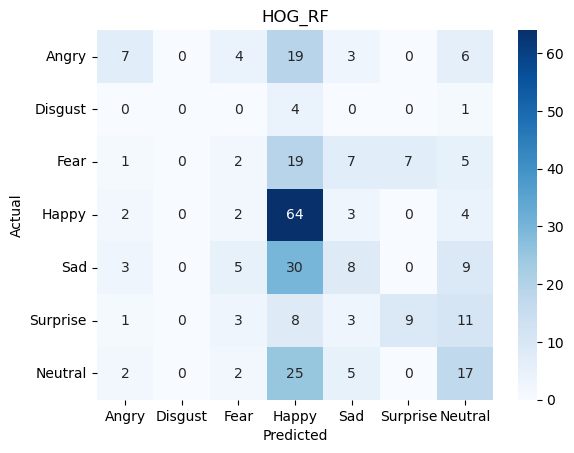

Extracting: Landmarks
Training: Landmarks_LR


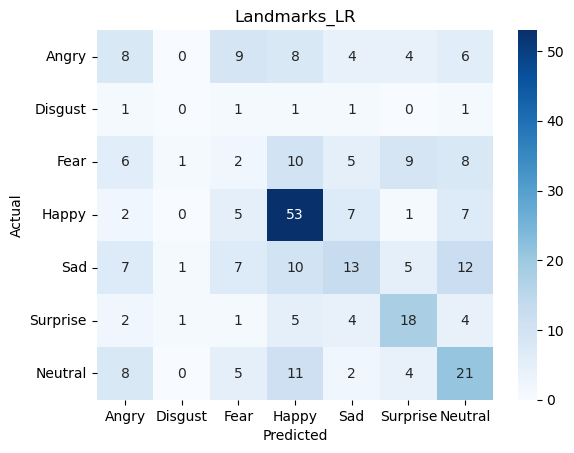

Training: Landmarks_SVM


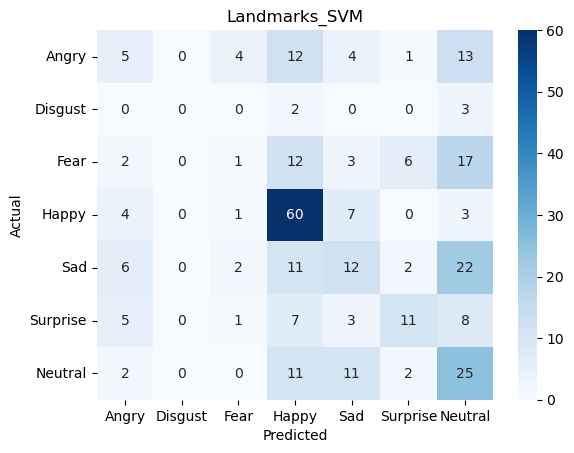

Training: Landmarks_RF


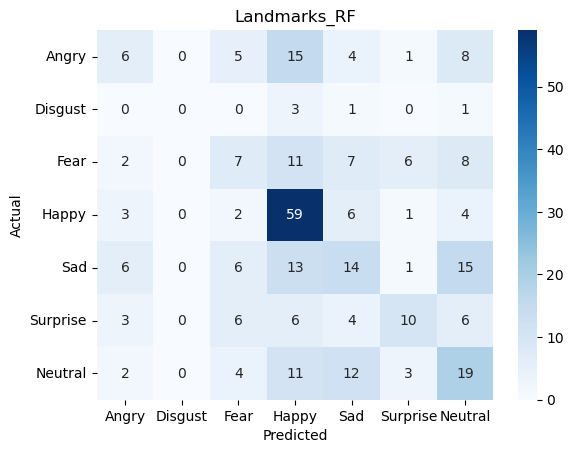

Extracting: PCA
Training: PCA_LR


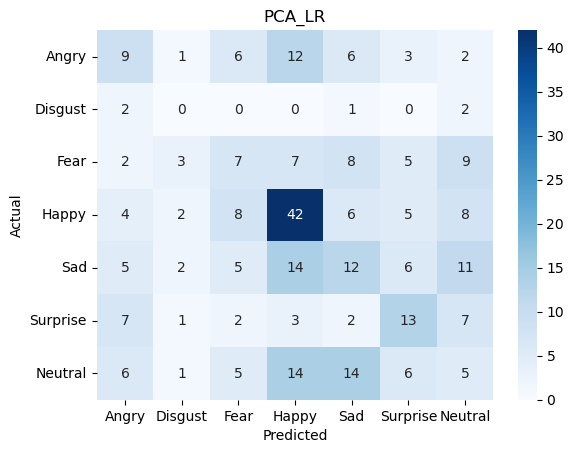

Training: PCA_SVM


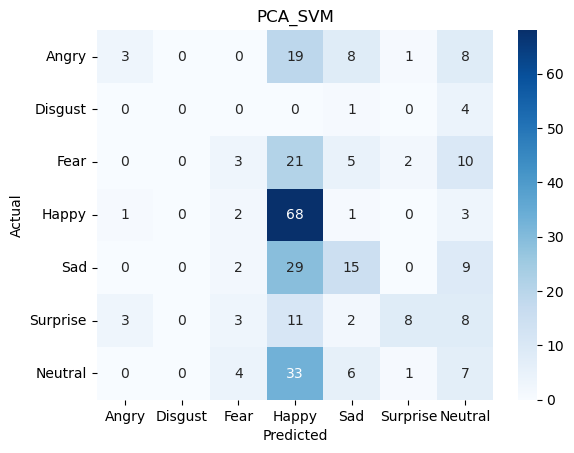

Training: PCA_RF


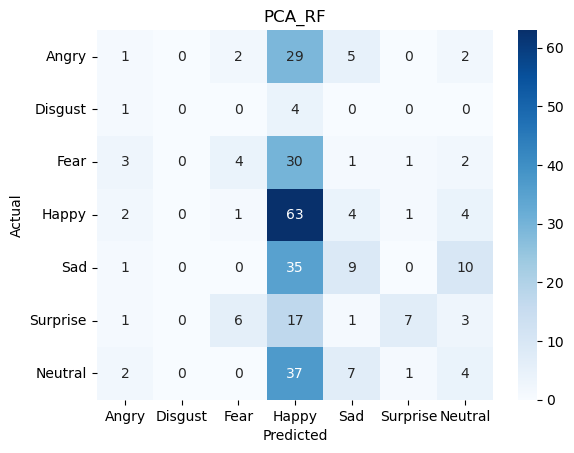

,model,acc,bal_acc,macro_f1
3,Landmarks_LR,0.382060,0.303284,0.289921
1,HOG_SVM,0.395349,0.299467,0.287585
5,Landmarks_RF,0.382060,0.289150,0.281044
4,Landmarks_SVM,0.378738,0.282180,0.260145
2,HOG_RF,0.355482,0.259647,0.245325
0,HOG_LR,0.302326,0.241178,0.239353
6,PCA_LR,0.292359,0.235593,0.232518
7,PCA_SVM,0.345515,0.242188,0.224826
8,PCA_RF,0.292359,0.200753,0.179788


In [11]:
import dlib
import importlib
import features
import dlib
from pathlib import Path

importlib.reload(features)

evaluate = features.evaluate
landmark_features = features.landmark_features

print("dlib version:", dlib.__version__)
print("Current directory:", Path.cwd())

images = fer_images(train.iloc[:1])

landmarks = landmark_features(images)

print("Landmark shape:", landmarks.shape)

rows = []
fitted = {}
stored_features = {}
for feature_name in ['HOG', 'Landmarks', 'PCA']:
    print('Extracting:', feature_name)
    try:
        Xtr, Xv, _, transformer = features_for(feature_name, train_imgs, val_imgs, None, MODELS_DIR)
    except (ImportError, FileNotFoundError, RuntimeError) as exc:
        print('Skipped', feature_name, 'because:', exc)
        continue
    stored_features[feature_name] = (Xtr, Xv, transformer)
    for model_name in ['LR', 'SVM', 'RF']:
        name = f'{feature_name}_{model_name}'
        print('Training:', name)
        model = make_model(model_name)
        model.fit(Xtr, y_train)
        predicted = model.predict(Xv)
        result = evaluate(y_val, predicted, name)
        result.update({'feature': feature_name, 'classifier': model_name})
        rows.append(result)
        fitted[name] = model
        joblib.dump({'model': model, 'feature': feature_name, 'transformer': transformer}, MODELS_DIR / f'{name}.pkl')
if not rows:
    raise RuntimeError('No experiments completed. Check your dependencies and data paths.')
results = pd.DataFrame(rows).sort_values('macro_f1', ascending=False)
results.to_csv(OUT_DIR / 'baseline_validation.csv', index=False)
results[['model', 'acc', 'bal_acc', 'macro_f1']]


### Baseline Results

I compared three classifiers (Logistic Regression, SVM and Random Forest) using HOG, facial landmarks and PCA features.

Landmarks with Logistic Regression achieved the highest macro F1 score (0.290), while HOG with SVM had the highest accuracy (39.5%). The difference between their macro F1 scores was very small.

Overall, landmark and HOG features performed better than PCA in these experiments. PCA with Random Forest gave the lowest macro F1 score (0.180).

The results are still relatively low, showing that recognizing different emotions from facial images is challenging.

## 7. Creative challenge — two changes

I take the strongest baseline based on validation macro F1, then test two changes:

1. **Class weights:** give rare emotions more importance.
2. **Parameter change:** adjust model regularisation (or tree depth for Random Forest).

I compare the original model, each change on its own, and both together. 

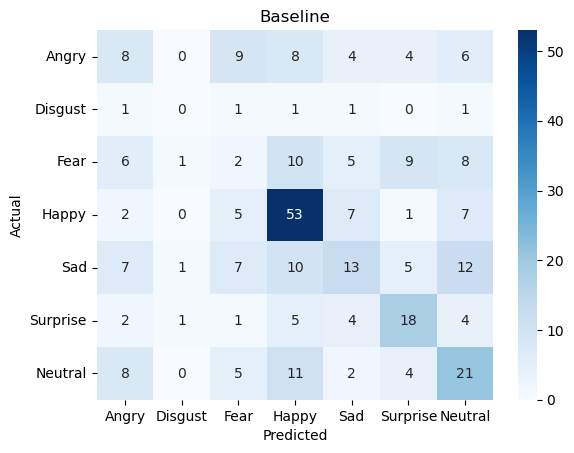

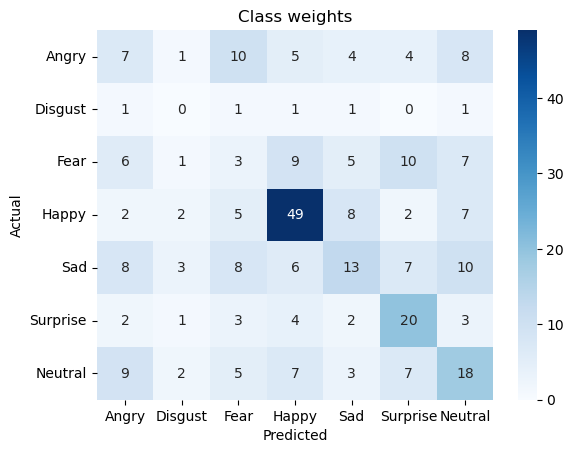

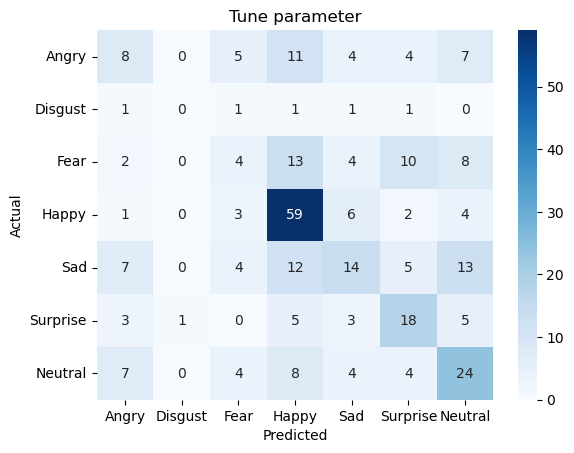

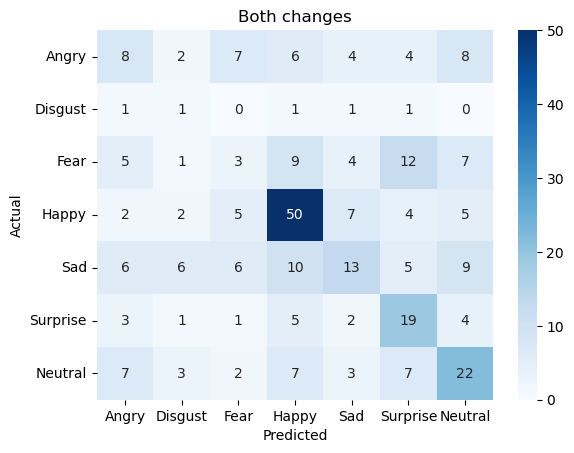

Best baseline: Landmarks_LR
Best variation: Tune parameter


,change,acc,bal_acc,macro_f1
0,Baseline,0.382060,0.303284,0.289921
1,Class weights,0.365449,0.295246,0.285072
2,Tune parameter,0.421927,0.332682,0.313942
3,Both changes,0.385382,0.336508,0.310058


In [12]:
best = results.iloc[0]
feat, clf = best['feature'], best['classifier']
Xtr, Xv, transformer = stored_features[feat]
variations = [('Baseline', None, 1.0), ('Class weights', 'balanced', 1.0),
              ('Tune parameter', None, 0.3), ('Both changes', 'balanced', 0.3)]
ablation = []
best_creative, best_score, best_change = None, -1, None
for label, weight, c in variations:
    if clf == 'RF':
        model = make_model('RF', weight)
        if c != 1.0:
            model.set_params(max_depth=15)
    else:
        model = make_model(clf, weight, c)
    model.fit(Xtr, y_train)
    predicted = model.predict(Xv)
    result = evaluate(y_val, predicted, label)
    result['change'] = label
    ablation.append(result)
    if result['macro_f1'] > best_score:
        best_creative, best_score, best_change = model, result['macro_f1'], label
ablation_table = pd.DataFrame(ablation)
ablation_table.to_csv(OUT_DIR / 'creative_ablation_validation.csv', index=False)
joblib.dump({'model': best_creative, 'feature': feat, 'transformer': transformer,
             'labels': EMOTIONS}, MODELS_DIR / 'final_selected_model.pkl')
print('Best baseline:', best['model'])
print('Best variation:', best_change)
ablation_table[['change', 'acc', 'bal_acc', 'macro_f1',]]


### Creative Challenge Results

I used Landmarks with Logistic Regression as my baseline because it had the highest macro F1 score among the nine models.

I tested two changes: adding class weights and tuning the regularization parameter.

Parameter tuning gave the best results, improving accuracy from 38.2% to 42.2% and macro F1 from 0.290 to 0.314.

Adding class weights alone did not improve the results. Combining both changes improved balanced accuracy, but the macro F1 was slightly lower than with parameter tuning alone.

Based on these results, I selected **Landmarks with Logistic Regression and parameter tuning** as my final model.

## 8. Final test 

**Do not run during model selection.** Once the model and settings are final, change `RUN_FINAL_TEST` to `True` and run this cell one time. Do not tune the model based on the test score. Note down the sample sizes and settings you used for your final experiment.

Selected features: Landmarks
Selected model: Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.3, max_iter=2000, random_state=42))])


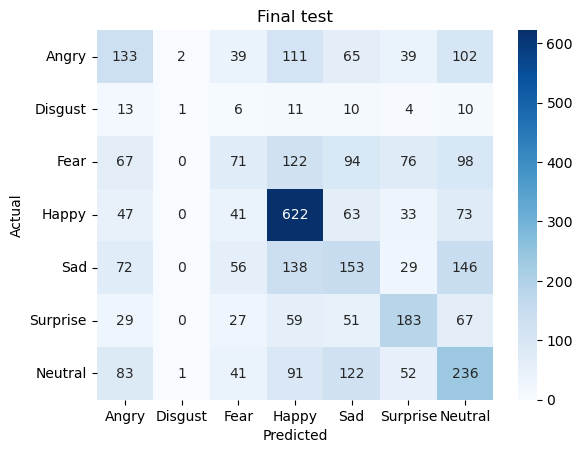

{'model': 'Final test', 'acc': 0.38980217330732797, 'bal_acc': 0.3150894265437683, 'macro_f1': 0.3084168594777162}
              precision    recall  f1-score   support

       Angry       0.30      0.27      0.28       491
     Disgust       0.25      0.02      0.03        55
        Fear       0.25      0.13      0.18       528
       Happy       0.54      0.71      0.61       879
         Sad       0.27      0.26      0.27       594
    Surprise       0.44      0.44      0.44       416
     Neutral       0.32      0.38      0.35       626

    accuracy                           0.39      3589
   macro avg       0.34      0.32      0.31      3589
weighted avg       0.37      0.39      0.37      3589



In [13]:
print("Selected features:", feat)
print("Selected model:", best_creative)
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    test = load_split(DATA_DIR / 'fer2013_test.csv', 0)
    test_imgs = fer_images(test)
    if feat == 'PCA':
        Xtest = transformer.transform(test_imgs.reshape(len(test_imgs), -1))
    elif feat == 'HOG':
        Xtest = hog_features(test_imgs)
    else:
        Xtest = landmark_features(test_imgs)
    test_pred = best_creative.predict(Xtest)
    test_result = evaluate(test.emotion.to_numpy(), test_pred, 'Final test')
    print(test_result)
    report = classification_report(test.emotion.to_numpy(), test_pred,
                                  labels=list(range(7)), target_names=EMOTIONS,
                                  zero_division=0)
    print(report)
    (OUT_DIR / 'classification_report_test.txt').write_text(report)
else:
    print('Final test skipped. Set RUN_FINAL_TEST = True once model selection is finished.')


### Final Test Results

I tested the selected Landmarks + Logistic Regression model on the FER2013 test set, which contains 3,589 images.

The model achieved 39.0% accuracy, 31.5% balanced accuracy and a macro F1 score of 0.308. These results were slightly lower than the validation results.

The model performed best on Happy (F1 = 0.61) and Surprise (F1 = 0.44). It struggled the most with Disgust (F1 = 0.03) and Fear (F1 = 0.18).

Overall, the model recognizes some emotions better than others, but its performance is still limited. The small training sample and the imbalance between emotion classes may have affected the results.

In [14]:
saved = joblib.load(MODELS_DIR / "final_selected_model.pkl")

print(saved["feature"])
print(saved["model"].predict(Xtest[:5]))

Landmarks
[6 4 4 2 0]


### Error Analysis — Misclassified Images

To better understand the mistakes made by my final model, I looked at some test images where the predicted emotion was different from the actual emotion.

Incorrect predictions: 2190
Correct predictions: 1399


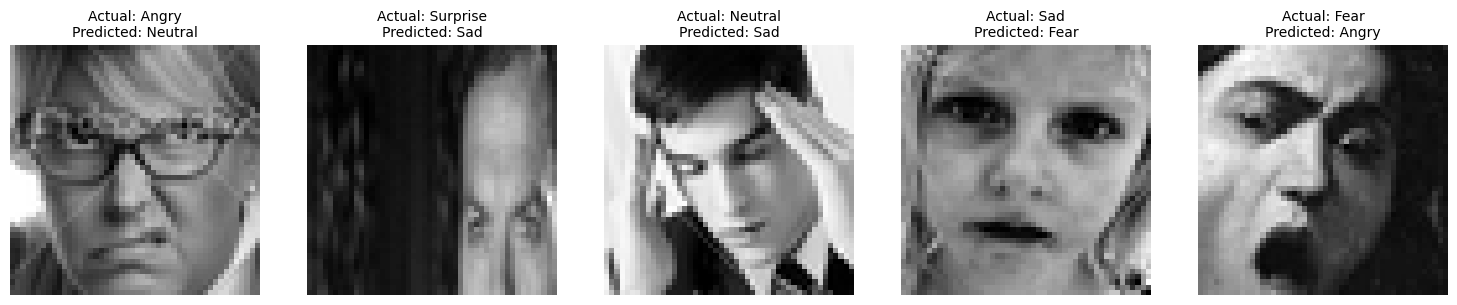

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Find images where the prediction was incorrect
y_test = test["emotion"].to_numpy()
wrong_indices = np.where(y_test != test_pred)[0]

print("Incorrect predictions:", len(wrong_indices))
print("Correct predictions:", len(y_test) - len(wrong_indices))

# Show five incorrectly classified images
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for ax, idx in zip(axes, wrong_indices[:5]):
    ax.imshow(test_imgs[idx], cmap="gray")
    ax.set_title(
        f"Actual: {EMOTIONS[y_test[idx]]}\n"
        f"Predicted: {EMOTIONS[test_pred[idx]]}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, test_pred, labels=range(7))

# Exclude correct predictions
np.fill_diagonal(cm, 0)

# Find the five most common mistakes
mistakes = []

for actual in range(7):
    for predicted in range(7):
        if actual != predicted:
            mistakes.append((
                EMOTIONS[actual],
                EMOTIONS[predicted],
                cm[actual, predicted]
            ))

mistakes.sort(key=lambda x: x[2], reverse=True)

print("Most common mistakes:")

for actual, predicted, count in mistakes[:5]:
    print(f"{actual} predicted as {predicted}: {count} images")

Most common mistakes:
Sad predicted as Neutral: 146 images
Sad predicted as Happy: 138 images
Fear predicted as Happy: 122 images
Neutral predicted as Sad: 122 images
Angry predicted as Happy: 111 images


### Phase B

In [17]:
from pathlib import Path

project = Path(r"C:\Users\LENOVO\Emotion_Recognition")

# Check the folders inside data
data_dir = project / "data"

if data_dir.exists():
    for item in data_dir.iterdir():
        print(item.name)
else:
    print("Data folder not found")

fer
KDEF_and_AKDEF


In [18]:
from pathlib import Path

kdef_dir = Path("../data/KDEF_and_AKDEF/KDEF")

images = [
    p for p in kdef_dir.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]
]

print("KDEF folder exists:", kdef_dir.exists())
print("KDEF images:", len(images))
print("First 5 images:", images[:5])

KDEF folder exists: True
KDEF images: 4900
First 5 images: [WindowsPath('../data/KDEF_and_AKDEF/KDEF/AF01/AF01AFFL.JPG'), WindowsPath('../data/KDEF_and_AKDEF/KDEF/AF01/AF01AFFR.JPG'), WindowsPath('../data/KDEF_and_AKDEF/KDEF/AF01/AF01AFHL.JPG'), WindowsPath('../data/KDEF_and_AKDEF/KDEF/AF01/AF01AFHR.JPG'), WindowsPath('../data/KDEF_and_AKDEF/KDEF/AF01/AF01AFS.JPG')]


In [19]:
emotion_map = {
    "AN": 0,  # Angry
    "DI": 1,  # Disgust
    "AF": 2,  # Fear
    "HA": 3,  # Happy
    "SA": 4,  # Sad
    "SU": 5,  # Surprise
    "NE": 6   # Neutral
}

valid_angles = {"FL", "HL", "S", "HR", "FR"}

rows = []
skipped = []

for path in images:
    name = path.stem.upper()

    if (
        len(name) >= 7
        and name[4:6] in emotion_map
        and name[6:] in valid_angles
    ):
        rows.append({
            "path": str(path),
            "subject": name[:4],
            "emotion": emotion_map[name[4:6]],
            "angle": name[6:]
        })
    else:
        skipped.append(name)

kdef_df = pd.DataFrame(rows)

print("Valid images:", len(kdef_df))
print("Skipped files:", skipped)
print("Subjects:", kdef_df["subject"].nunique())
print("Images per emotion:")
print(kdef_df["emotion"].value_counts().sort_index())

Valid images: 4898
Skipped files: ['AF31V', 'AM31H']
Subjects: 140
Images per emotion:
emotion
0    700
1    700
2    700
3    700
4    699
5    699
6    700
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import GroupShuffleSplit

# Split subjects into training/validation and test groups
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_val_idx, test_idx = next(
    splitter.split(kdef_df, groups=kdef_df["subject"])
)

train_val = kdef_df.iloc[train_val_idx]
kdef_test = kdef_df.iloc[test_idx]

# Split remaining subjects into training and validation
train_idx, val_idx = next(
    splitter.split(train_val, groups=train_val["subject"])
)

kdef_train = train_val.iloc[train_idx].reset_index(drop=True)
kdef_val = train_val.iloc[val_idx].reset_index(drop=True)
kdef_test = kdef_test.reset_index(drop=True)

print("Training:", len(kdef_train))
print("Validation:", len(kdef_val))
print("Test:", len(kdef_test))

# Check that subjects do not overlap
print("Train/Validation overlap:",
      len(set(kdef_train.subject) & set(kdef_val.subject)))

print("Train/Test overlap:",
      len(set(kdef_train.subject) & set(kdef_test.subject)))

print("Validation/Test overlap:",
      len(set(kdef_val.subject) & set(kdef_test.subject)))

Training: 3113
Validation: 805
Test: 980
Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0


Image shape: (48, 48)
Minimum value: 0.019607844
Maximum value: 0.5372549


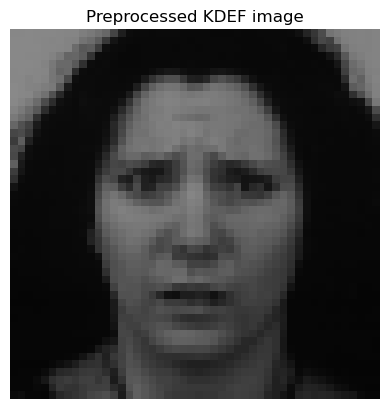

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from preprocess import preprocess_kdef_image

# Start with a frontal face
front_images = kdef_train[kdef_train["angle"] == "S"]
image_path = front_images.iloc[0]["path"]

# Preprocess it
processed = preprocess_kdef_image(image_path)

print("Image shape:", processed.shape)
print("Minimum value:", processed.min())
print("Maximum value:", processed.max())

plt.imshow(processed, cmap="gray", vmin=0, vmax=1)
plt.title("Preprocessed KDEF image")
plt.axis("off")
plt.show()

4.1 Process each image and records any failures instead of stopping the entire notebook.

In [27]:
import numpy as np
import cv2
from tqdm.auto import tqdm

def prepare_kdef(df):
    processed_images = []
    labels = []
    successful_rows = []
    failed_images = []

    for idx, row in tqdm(df.iterrows(), total=len(df)):
        try:
            # Detect, crop and resize the face
            img = preprocess_kdef_image(row["path"])

            # Convert to the same pixel range as FER2013
            img = (img * 255).astype(np.uint8)

            processed_images.append(img)
            labels.append(row["emotion"])
            successful_rows.append(idx)

        except (ValueError, cv2.error) as e:
            # Keep track of images that could not be processed
            failed_images.append((row["path"], str(e)))

    return (
        np.array(processed_images),
        np.array(labels),
        df.loc[successful_rows].reset_index(drop=True),
        failed_images
    )

4.2 Process training and validation data

In [28]:
X_train_img, y_train, train_info, train_failed = prepare_kdef(kdef_train)

X_val_img, y_val, val_info, val_failed = prepare_kdef(kdef_val)

print("Training images:", X_train_img.shape)
print("Validation images:", X_val_img.shape)

print("Failed training images:", len(train_failed))
print("Failed validation images:", len(val_failed))

  0%|          | 0/3113 [00:00<?, ?it/s]

100%|██████████| 805/805 [00:34<00:00, 23.24it/s]

Training images: (1866, 48, 48)
Validation images: (454, 48, 48)
Failed training images: 1247
Failed validation images: 351


4.3 Check which angles failed

In [29]:
# Check failed images by camera angle
failed_paths = [path for path, error in train_failed]

failed_df = kdef_train[kdef_train["path"].isin(failed_paths)]

print("Failures by angle:")
print(failed_df["angle"].value_counts())

print("\nSuccessfully processed:")
print(len(train_info))

Failures by angle:
angle
FR    546
FL    496
HL    123
HR     82
Name: count, dtype: int64

Successfully processed:
1866


4.4 Display some processed faces

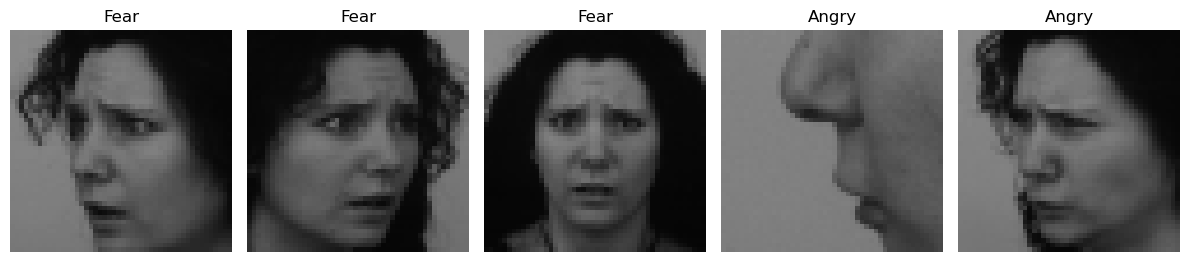

In [30]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, ax in enumerate(axes):
    ax.imshow(X_train_img[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(EMOTIONS[y_train[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

4.5 Save the processed data

In [31]:
from pathlib import Path

output_dir = Path("../data/kdef_processed")
output_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    output_dir / "kdef_train.npz",
    images=X_train_img,
    labels=y_train
)

np.savez_compressed(
    output_dir / "kdef_validation.npz",
    images=X_val_img,
    labels=y_val
)

print("Processed datasets saved!")

Processed datasets saved!


In [32]:
print("Training images:", X_train_img.shape)
print("Validation images:", X_val_img.shape)

print("Failed training:", len(train_failed))
print("Failed validation:", len(val_failed))

Training images: (1866, 48, 48)
Validation images: (454, 48, 48)
Failed training: 1247
Failed validation: 351


Extract HOG pictures

In [33]:
from features import hog_features

# Extract HOG features from the processed images
X_train_hog = hog_features(X_train_img)
X_val_hog = hog_features(X_val_img)

print("Training HOG shape:", X_train_hog.shape)
print("Validation HOG shape:", X_val_hog.shape)

Training HOG shape: (1866, 900)
Validation HOG shape: (454, 900)


Train the first model: HOG + Logistic Regression

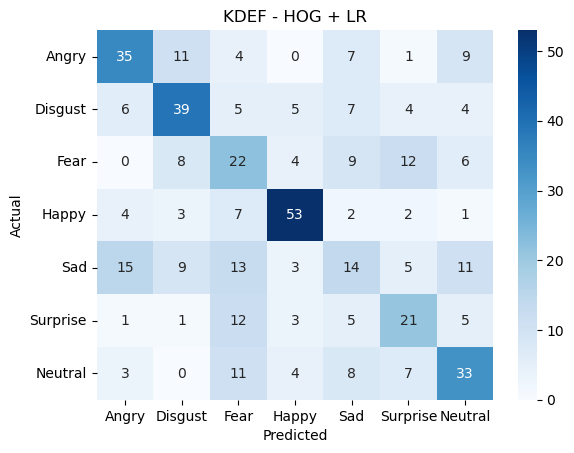

{'model': 'KDEF - HOG + LR', 'acc': 0.4779735682819383, 'bal_acc': 0.47339968080862554, 'macro_f1': 0.4697109652924439}


In [34]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from features import evaluate

# Create the model
hog_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

# Train using KDEF training images
hog_lr.fit(X_train_hog, y_train)

# Predict validation emotions
predictions = hog_lr.predict(X_val_hog)

# Evaluate the model
result = evaluate(y_val, predictions, "KDEF - HOG + LR")

print(result)

Save the model

In [35]:
import joblib
from pathlib import Path

models_dir = Path("../models/phase_b")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(hog_lr, models_dir / "kdef_hog_lr.pkl")

print("Model saved")

Model saved


Train HOG + SVM

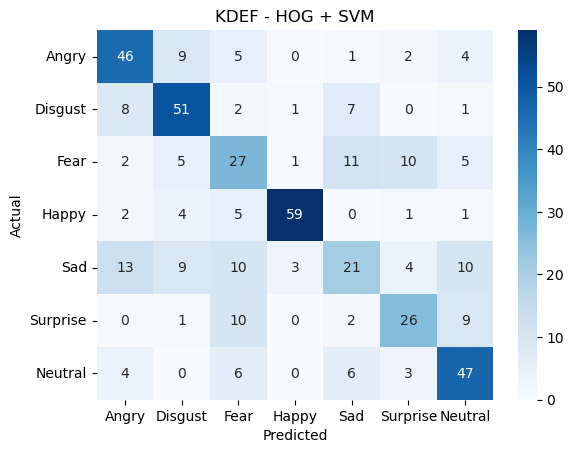

{'model': 'KDEF - HOG + SVM', 'acc': 0.6101321585903083, 'bal_acc': 0.6044276952575041, 'macro_f1': 0.5993051314031532}


In [36]:
from sklearn.svm import SVC

# Train SVM using HOG features
hog_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, random_state=42)
)

hog_svm.fit(X_train_hog, y_train)

pred_svm = hog_svm.predict(X_val_hog)

result_svm = evaluate(y_val, pred_svm, "KDEF - HOG + SVM")

print(result_svm)

HOG + Random Forest

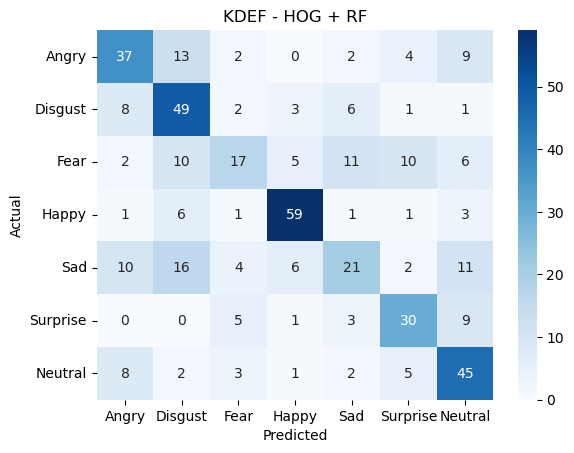

{'model': 'KDEF - HOG + RF', 'acc': 0.5682819383259912, 'bal_acc': 0.5653128509747055, 'macro_f1': 0.5519280885660082}


In [37]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest using HOG features
hog_rf = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    n_jobs=-1
)

hog_rf.fit(X_train_hog, y_train)

pred_rf = hog_rf.predict(X_val_hog)

result_rf = evaluate(y_val, pred_rf, "KDEF - HOG + RF")

print(result_rf)

Compare

In [38]:
# Add the results to one table
hog_results = pd.DataFrame([
    result,
    result_svm,
    result_rf
])

display(hog_results.round(3))

,model,acc,bal_acc,macro_f1
0,KDEF - HOG + LR,0.478,0.473,0.470
1,KDEF - HOG + SVM,0.610,0.604,0.599
2,KDEF - HOG + RF,0.568,0.565,0.552


Prepare Landmark Experiments

In [39]:
from features import landmark_features

# Extract 68 facial landmarks (136 features)
X_train_landmarks = landmark_features(X_train_img)
X_val_landmarks = landmark_features(X_val_img)

print("Training:", X_train_landmarks.shape)
print("Validation:", X_val_landmarks.shape)

Training: (1866, 136)
Validation: (454, 136)


Train the three Landmark models

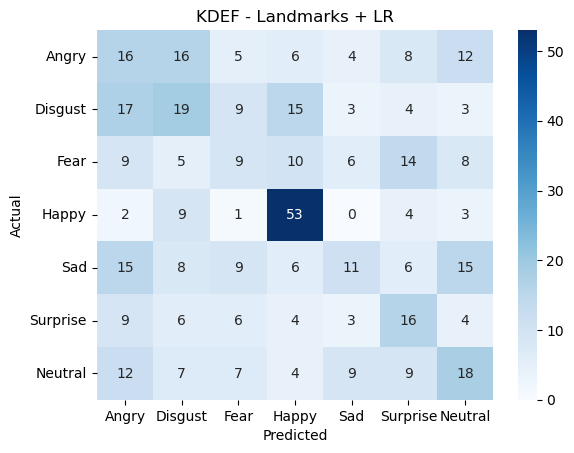

{'model': 'KDEF - Landmarks + LR', 'acc': 0.31277533039647576, 'bal_acc': 0.30815572849985096, 'macro_f1': 0.29443775371331243}


In [40]:
# Logistic Regression with facial landmarks
landmarks_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

landmarks_lr.fit(X_train_landmarks, y_train)

pred_lr = landmarks_lr.predict(X_val_landmarks)

result_landmarks_lr = evaluate(
    y_val, pred_lr, "KDEF - Landmarks + LR"
)

print(result_landmarks_lr)

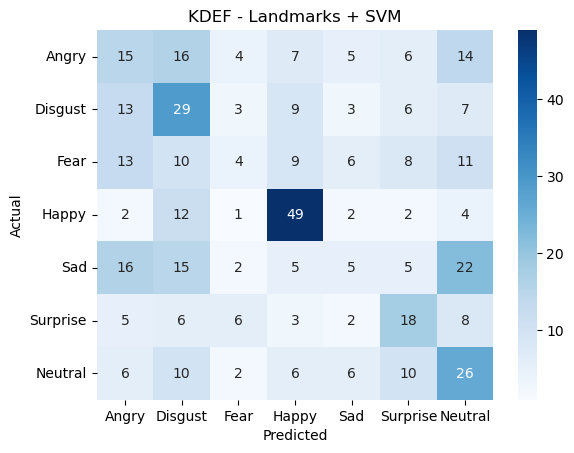

{'model': 'KDEF - Landmarks + SVM', 'acc': 0.32158590308370044, 'bal_acc': 0.31780908610228054, 'macro_f1': 0.2932486182520116}


In [41]:
# SVM with facial landmarks
landmarks_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, random_state=42)
)

landmarks_svm.fit(X_train_landmarks, y_train)

pred_svm = landmarks_svm.predict(X_val_landmarks)

result_landmarks_svm = evaluate(
    y_val, pred_svm, "KDEF - Landmarks + SVM"
)

print(result_landmarks_svm)

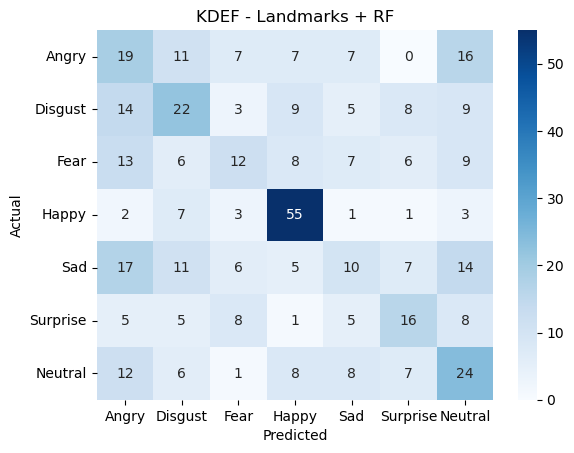

{'model': 'KDEF - Landmarks + RF', 'acc': 0.34801762114537443, 'bal_acc': 0.3426149777184416, 'macro_f1': 0.3316270555363707}


In [42]:
# Random Forest with facial landmarks
landmarks_rf = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    n_jobs=-1
)

landmarks_rf.fit(X_train_landmarks, y_train)

pred_rf = landmarks_rf.predict(X_val_landmarks)

result_landmarks_rf = evaluate(
    y_val, pred_rf, "KDEF - Landmarks + RF"
)

print(result_landmarks_rf)

Compare and save models

In [43]:
# Compare the three models
landmarks_results = pd.DataFrame([
    result_landmarks_lr,
    result_landmarks_svm,
    result_landmarks_rf
])

display(landmarks_results.round(3))

# Save trained models
joblib.dump(landmarks_lr, models_dir / "kdef_landmarks_lr.pkl")
joblib.dump(landmarks_svm, models_dir / "kdef_landmarks_svm.pkl")
joblib.dump(landmarks_rf, models_dir / "kdef_landmarks_rf.pkl")

print("Landmark models saved!")

,model,acc,bal_acc,macro_f1
0,KDEF - Landmarks + LR,0.313,0.308,0.294
1,KDEF - Landmarks + SVM,0.322,0.318,0.293
2,KDEF - Landmarks + RF,0.348,0.343,0.332


Landmark models saved!


Extract PCA features

In [44]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Convert images into one row per image
X_train_flat = X_train_img.reshape(len(X_train_img), -1)
X_val_flat = X_val_img.reshape(len(X_val_img), -1)

# Fit PCA using only training images
pca_transformer = make_pipeline(
    StandardScaler(),
    PCA(n_components=100, random_state=42)
)

X_train_pca = pca_transformer.fit_transform(X_train_flat)
X_val_pca = pca_transformer.transform(X_val_flat)

print("Training shape:", X_train_pca.shape)
print("Validation shape:", X_val_pca.shape)

Training shape: (1866, 100)
Validation shape: (454, 100)


Train PCA + Logistic Regression

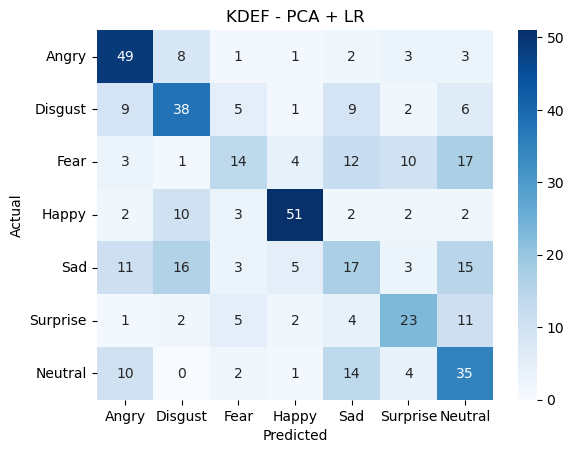

{'model': 'KDEF - PCA + LR', 'acc': 0.5, 'bal_acc': 0.4949098280458167, 'macro_f1': 0.4869477931557987}


In [45]:
pca_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

pca_lr.fit(X_train_pca, y_train)

pred_pca_lr = pca_lr.predict(X_val_pca)

result_pca_lr = evaluate(
    y_val, pred_pca_lr, "KDEF - PCA + LR"
)

print(result_pca_lr)

PCA + SVM

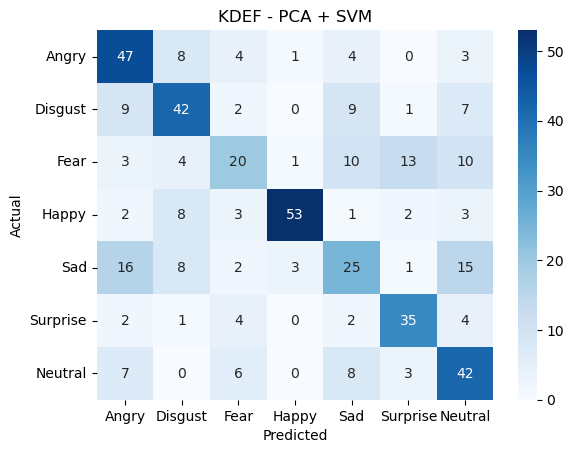

{'model': 'KDEF - PCA + SVM', 'acc': 0.5814977973568282, 'bal_acc': 0.5840208087223886, 'macro_f1': 0.577839113379763}


In [46]:
pca_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, random_state=42)
)

pca_svm.fit(X_train_pca, y_train)

pred_pca_svm = pca_svm.predict(X_val_pca)

result_pca_svm = evaluate(
    y_val, pred_pca_svm, "KDEF - PCA + SVM"
)

print(result_pca_svm)

PCA + Random Forest

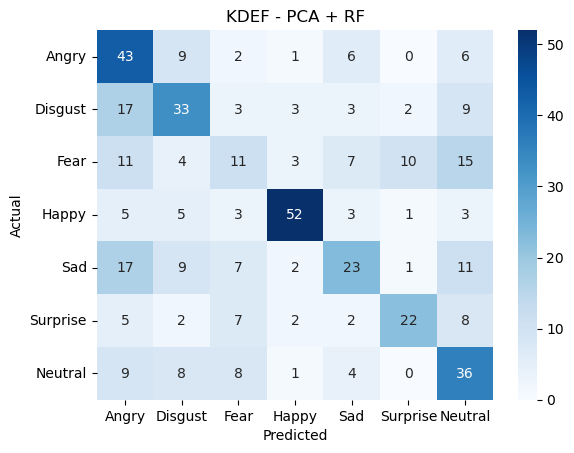

{'model': 'KDEF - PCA + RF', 'acc': 0.4845814977973568, 'bal_acc': 0.4783041449483828, 'macro_f1': 0.47532087166730036}


In [47]:
pca_rf = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    n_jobs=-1
)

pca_rf.fit(X_train_pca, y_train)

pred_pca_rf = pca_rf.predict(X_val_pca)

result_pca_rf = evaluate(
    y_val, pred_pca_rf, "KDEF - PCA + RF"
)

print(result_pca_rf)

compare models and save

In [48]:
pca_results = pd.DataFrame([
    result_pca_lr,
    result_pca_svm,
    result_pca_rf
])

display(pca_results.round(3))

# Save each model
joblib.dump(
    {"model": pca_lr, "transformer": pca_transformer},
    models_dir / "kdef_pca_lr.pkl"
)

joblib.dump(
    {"model": pca_svm, "transformer": pca_transformer},
    models_dir / "kdef_pca_svm.pkl"
)

joblib.dump(
    {"model": pca_rf, "transformer": pca_transformer},
    models_dir / "kdef_pca_rf.pkl"
)

print("PCA models saved!")

,model,acc,bal_acc,macro_f1
0,KDEF - PCA + LR,0.500,0.495,0.487
1,KDEF - PCA + SVM,0.581,0.584,0.578
2,KDEF - PCA + RF,0.485,0.478,0.475


PCA models saved!


Compare all nine models

In [49]:
# Combine results from all three feature types
all_results = pd.concat([
    hog_results,
    landmarks_results,
    pca_results
], ignore_index=True)

# Sort by macro F1
all_results = all_results.sort_values(
    "macro_f1", ascending=False
)

display(all_results.round(3))

,model,acc,bal_acc,macro_f1
1,KDEF - HOG + SVM,0.610,0.604,0.599
7,KDEF - PCA + SVM,0.581,0.584,0.578
2,KDEF - HOG + RF,0.568,0.565,0.552
6,KDEF - PCA + LR,0.500,0.495,0.487
8,KDEF - PCA + RF,0.485,0.478,0.475
0,KDEF - HOG + LR,0.478,0.473,0.470
5,KDEF - Landmarks + RF,0.348,0.343,0.332
3,KDEF - Landmarks + LR,0.313,0.308,0.294
4,KDEF - Landmarks + SVM,0.322,0.318,0.293


### KDEF Baseline Results

I tested Logistic Regression, SVM and Random Forest using HOG, PCA and facial landmark features.

HOG with SVM performed best, reaching 61.0% accuracy and a macro F1 score of 0.599. PCA with SVM was the second-best model, with a macro F1 of 0.578.

The landmark models performed much worse, with macro F1 scores below 0.34.

Overall, HOG and PCA seem to work better than facial landmarks for this dataset. This may be because they capture more visual information from the images, while landmarks mainly describe the positions of facial features.

Preprocess test images

In [50]:
# Process the KDEF test images
X_test_img, y_test, test_info, test_failed = prepare_kdef(kdef_test)

print("Test images processed:", len(X_test_img))
print("Failed images:", len(test_failed))

100%|██████████| 980/980 [00:47<00:00, 20.80it/s]


Test images processed: 577
Failed images: 403


Extract features and predict

In [54]:
# Use the same HOG features as during training
X_test_hog = hog_features(X_test_img)

# Predict with the already trained SVM
test_pred = hog_svm.predict(X_test_hog)

Evaluate Results

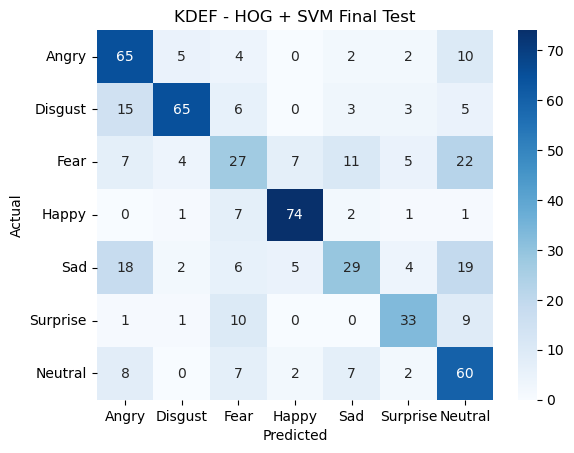

{'model': 'KDEF - HOG + SVM Final Test', 'acc': 0.6117850953206239, 'bal_acc': 0.6075269853707749, 'macro_f1': 0.6030009995192118}
              precision    recall  f1-score   support

       Angry       0.57      0.74      0.64        88
     Disgust       0.83      0.67      0.74        97
        Fear       0.40      0.33      0.36        83
       Happy       0.84      0.86      0.85        86
         Sad       0.54      0.35      0.42        83
    Surprise       0.66      0.61      0.63        54
     Neutral       0.48      0.70      0.57        86

    accuracy                           0.61       577
   macro avg       0.62      0.61      0.60       577
weighted avg       0.62      0.61      0.61       577



In [55]:
# Evaluate the model on unseen subjects
test_result = evaluate(
    y_test,
    test_pred,
    "KDEF - HOG + SVM Final Test"
)

print(test_result)

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    test_pred,
    labels=range(7),
    target_names=EMOTIONS,
    zero_division=0
))

Save final model

In [56]:
import joblib

joblib.dump(
    {
        "model": hog_svm,
        "feature": "HOG",
        "labels": EMOTIONS
    },
    models_dir / "kdef_final_hog_svm.pkl"
)

print("Final KDEF model saved!")

Final KDEF model saved!


In [57]:
# check which angles were excluded

failed_paths = [path for path, error in test_failed]

failed_df = kdef_test[
    kdef_test["path"].isin(failed_paths)
]

print("Failed images by angle:")
print(failed_df["angle"].value_counts())

print("\nFailed images by emotion:")
print(failed_df["emotion"].value_counts().sort_index())

Failed images by angle:
angle
FR    167
FL    162
HL     43
HR     31
Name: count, dtype: int64

Failed images by emotion:
emotion
0    52
1    43
2    57
3    54
4    57
5    86
6    54
Name: count, dtype: int64


### KDEF Final Test Results

I selected HOG with SVM because it had the best validation results among the nine baseline models.

On the KDEF test set, the model achieved 61.2% accuracy, 60.8% balanced accuracy and a macro F1 score of 0.603. These results were close to the validation scores.

The model performed best on Happy (F1 = 0.85) and Disgust (F1 = 0.74). It struggled more with Fear (F1 = 0.36) and Sad (F1 = 0.42).

One limitation is that only 577 out of 980 test images were successfully preprocessed. The remaining images could not be processed by our face detector, so these results do not represent the complete KDEF test set.

## Cross Dataset Evaluation

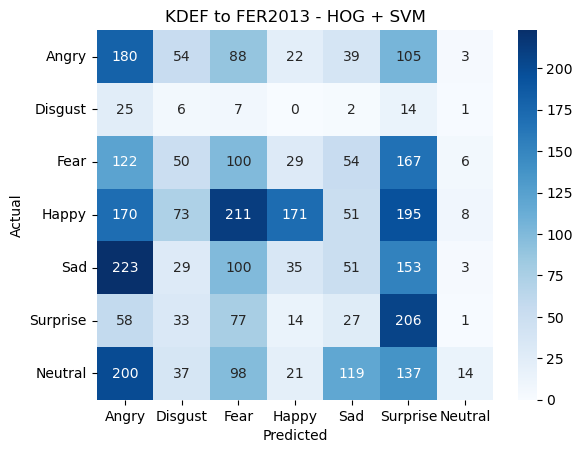

{'model': 'KDEF to FER2013 - HOG + SVM', 'acc': 0.20284201727500697, 'bal_acc': 0.20900542663413843, 'macro_f1': 0.16929652678011894}


In [58]:
from features import fer_images, hog_features
import pandas as pd

# Load the FER2013 test set
fer_test = pd.read_csv("../data/fer/fer2013_test.csv")

# Convert pixel strings into images
fer_test_images = fer_images(fer_test)

# Extract the same HOG features used for KDEF
X_fer_hog = hog_features(fer_test_images)
y_fer_test = fer_test["emotion"].to_numpy()

# Predict using the KDEF-trained model
fer_predictions = hog_svm.predict(X_fer_hog)

# Evaluate on FER2013
cross_result = evaluate(
    y_fer_test,
    fer_predictions,
    "KDEF to FER2013 - HOG + SVM"
)

print(cross_result)

### Preprocessing Limitations

During preprocessing, 403 out of 980 KDEF test images could not be processed by the face detector.

Most failures occurred with full side-profile images (167 from the right and 162 from the left). This is probably because the Haar Cascade detector works better with frontal faces.

I also noticed that Surprise had the most failed images (86).

Since these images were excluded, our final results are based on 577 images instead of the full test set. This means the results may not represent how the model would perform on all KDEF images.

### Cross-Dataset Evaluation: KDEF to FER2013

I tested the HOG + SVM model trained on KDEF using the FER2013 test set.

The model achieved 20.3% accuracy and a macro F1 score of 0.169, compared to 61.2% accuracy and 0.603 macro F1 when tested on KDEF.

The performance dropped significantly when using a different dataset. This could be because KDEF contains posed expressions under controlled conditions, while FER2013 contains more varied facial images.

The results suggest that the model does not generalize well to images from a different dataset.

In [59]:
#Load person's A HOG model
import joblib
from pathlib import Path

model_path = Path("../models/phase_a/HOG_SVM.pkl")

saved = joblib.load(model_path)

# The saved file contains the model and feature information
fer_model = saved["model"]

print("Feature type:", saved["feature"])
print("Model loaded:", fer_model)

Feature type: HOG
Model loaded: Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(cache_size=500))])


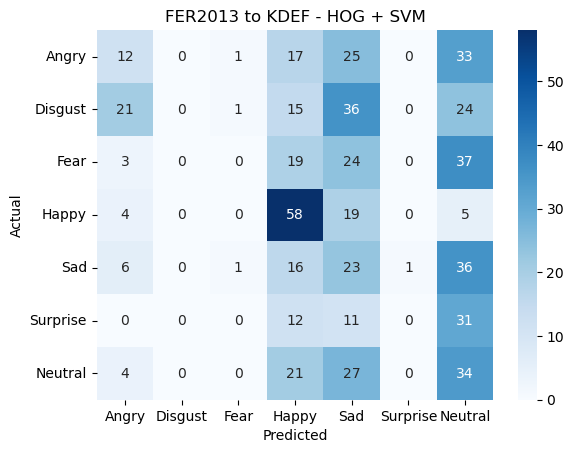

{'model': 'FER2013 to KDEF - HOG + SVM', 'acc': 0.22010398613518198, 'bal_acc': 0.21189135885129162, 'macro_f1': 0.15322414118197347}


In [60]:
# HOG features from the KDEF test images
X_kdef_hog = hog_features(X_test_img)

# Predict using the FER2013 model
fer_to_kdef_pred = fer_model.predict(X_kdef_hog)

# Evaluate
fer_to_kdef_result = evaluate(
    y_test,
    fer_to_kdef_pred,
    "FER2013 to KDEF - HOG + SVM"
)

print(fer_to_kdef_result)

### Cross-Dataset Evaluation

I tested how well the HOG + SVM models performed when trained on one dataset and tested on the other.

The model trained on KDEF achieved 20.3% accuracy and 0.169 macro F1 when tested on FER2013. In the opposite direction, the FER2013 model achieved 22.0% accuracy and 0.153 macro F1 on KDEF.

Both models performed much worse when tested on a different dataset. This suggests that they learned patterns that work better on their original dataset.

One possible reason is that KDEF contains posed facial expressions in controlled conditions, while FER2013 has more variation in faces, lighting and image quality.

The KDEF evaluation was also limited to images that were successfully detected and cropped during preprocessing.

In [61]:
from features import fer_images, landmark_features
import pandas as pd
import numpy as np

# Load FER2013 datasets
fer_train = pd.read_csv("../data/fer/fer2013_train.csv")
fer_test = pd.read_csv("../data/fer/fer2013_test.csv")

# Use the same 999-image training sample as Person A
fer_train = (
    fer_train.groupby("emotion", group_keys=False)
    .sample(frac=1000 / len(fer_train), random_state=42)
    .reset_index(drop=True)
)

# Convert pixel strings to images
fer_train_img = fer_images(fer_train)
fer_test_img = fer_images(fer_test)

y_fer_train = fer_train["emotion"].to_numpy()
y_fer_test = fer_test["emotion"].to_numpy()

print("FER2013 training:", len(fer_train_img))
print("FER2013 test:", len(fer_test_img))

FER2013 training: 999
FER2013 test: 3589


In [63]:
import joblib
from pathlib import Path

# Load Person A's final model
model_path = Path("../models/phase_a/final_selected_model.pkl")

saved_a = joblib.load(model_path)

fer_landmark_model = saved_a["model"]

print("Features:", saved_a["feature"])
print("Model:", fer_landmark_model)

Features: Landmarks
Model: Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.3, max_iter=2000, random_state=42))])


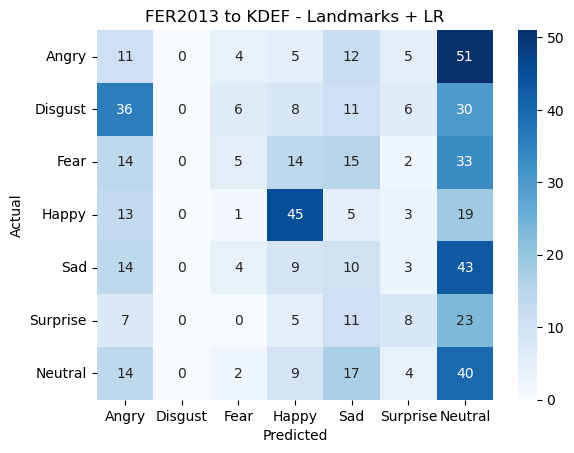

{'model': 'FER2013 to KDEF - Landmarks + LR', 'acc': 0.20623916811091855, 'bal_acc': 0.20603473324823843, 'macro_f1': 0.1800701644265872}


In [64]:
# Extract landmarks from the processed KDEF images
X_kdef_landmarks = landmark_features(X_test_img)

pred = fer_landmark_model.predict(X_kdef_landmarks)

result_fer_to_kdef_landmarks = evaluate(
    y_test,
    pred,
    "FER2013 to KDEF - Landmarks + LR"
)

print(result_fer_to_kdef_landmarks)

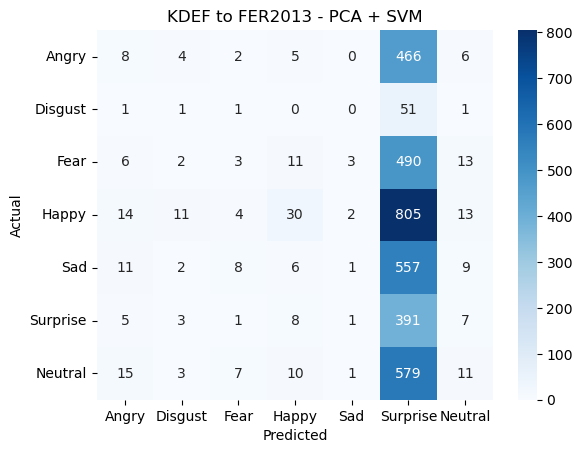

{'model': 'KDEF to FER2013 - PCA + SVM', 'acc': 0.1239899693507941, 'bal_acc': 0.1476351201485968, 'macro_f1': 0.05306173304944011}


In [65]:
# Flatten FER2013 images
fer_test_flat = fer_test_img.reshape(len(fer_test_img), -1)

# Use the PCA transformation fitted on KDEF
X_fer_pca = pca_transformer.transform(fer_test_flat)

# Predict using KDEF-trained PCA + SVM
pred = pca_svm.predict(X_fer_pca)

result_kdef_to_fer_pca = evaluate(
    y_fer_test,
    pred,
    "KDEF to FER2013 - PCA + SVM"
)

print(result_kdef_to_fer_pca)

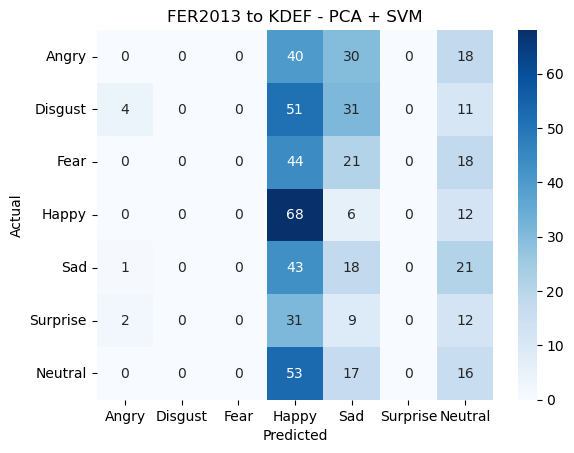

{'model': 'FER2013 to KDEF - PCA + SVM', 'acc': 0.17677642980935876, 'bal_acc': 0.17051595084657567, 'macro_f1': 0.0941876272852058}


In [66]:
# Load Person A's PCA + SVM model
saved_pca = joblib.load(
    "../models/phase_a/PCA_SVM.pkl"
)

fer_pca_model = saved_pca["model"]
fer_pca_transformer = saved_pca["transformer"]

# Flatten KDEF test images
kdef_test_flat = X_test_img.reshape(len(X_test_img), -1)

# Apply FER2013's PCA transformation
X_kdef_pca = fer_pca_transformer.transform(kdef_test_flat)

# Predict using FER2013-trained PCA + SVM
pred = fer_pca_model.predict(X_kdef_pca)

result_fer_to_kdef_pca = evaluate(
    y_test,
    pred,
    "FER2013 to KDEF - PCA + SVM"
)

print(result_fer_to_kdef_pca)

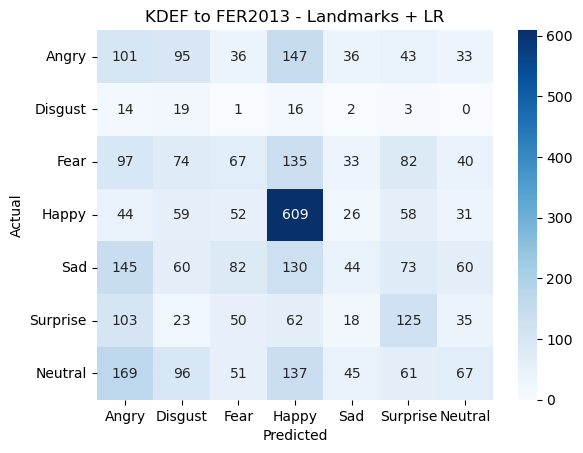

{'model': 'KDEF to FER2013 - Landmarks + LR', 'acc': 0.2875452772359989, 'bal_acc': 0.2646382134728427, 'macro_f1': 0.21912057338221252}


In [68]:
# KDEF -> FER2013 using facial landmarks

from features import landmark_features

# Extract landmarks from FER2013 test images
X_fer_landmarks = landmark_features(fer_test_img)

# Use the KDEF-trained Logistic Regression model
pred_kdef_to_fer_landmarks = landmarks_lr.predict(X_fer_landmarks)

# Evaluate predictions
result_kdef_to_fer_landmarks = evaluate(
    y_fer_test,
    pred_kdef_to_fer_landmarks,
    "KDEF to FER2013 - Landmarks + LR"
)

print(result_kdef_to_fer_landmarks)

In [69]:
cross_results = pd.DataFrame([
    cross_result,                  # KDEF → FER2013 HOG
    fer_to_kdef_result,            # FER2013 → KDEF HOG
    result_kdef_to_fer_landmarks,
    result_fer_to_kdef_landmarks,
    result_kdef_to_fer_pca,
    result_fer_to_kdef_pca
])

display(
    cross_results[
        ["model", "acc", "bal_acc", "macro_f1"]
    ].round(3)
)

,model,acc,bal_acc,macro_f1
0,KDEF to FER2013 - HOG + SVM,0.203,0.209,0.169
1,FER2013 to KDEF - HOG + SVM,0.220,0.212,0.153
2,KDEF to FER2013 - Landmarks + LR,0.288,0.265,0.219
3,FER2013 to KDEF - Landmarks + LR,0.206,0.206,0.180
4,KDEF to FER2013 - PCA + SVM,0.124,0.148,0.053
5,FER2013 to KDEF - PCA + SVM,0.177,0.171,0.094


### Cross-Dataset Results

I tested HOG, facial landmarks and PCA to see how well the models worked on a different dataset.

Overall, the performance dropped a lot compared to testing on the original dataset.

Landmarks with Logistic Regression performed best in both directions, reaching a macro F1 of 0.219 for KDEF to FER2013 and 0.180 for FER2013 to KDEF.

HOG with SVM performed better when tested on KDEF itself, but did not generalize as well to FER2013. PCA gave the lowest cross-dataset results.

This could be because KDEF and FER2013 have different image conditions. KDEF contains posed expressions, while FER2013 has more variation in image quality, lighting and faces.

The results suggest that a model performing well on one dataset does not necessarily work well on another.

Check class distribution

In [70]:
from features import EMOTIONS
import pandas as pd

counts = pd.Series(y_train).value_counts().sort_index()
counts.index = EMOTIONS

print(counts)

Angry       280
Disgust     283
Fear        260
Happy       294
Sad         259
Surprise    216
Neutral     274
Name: count, dtype: int64


Training: Baseline


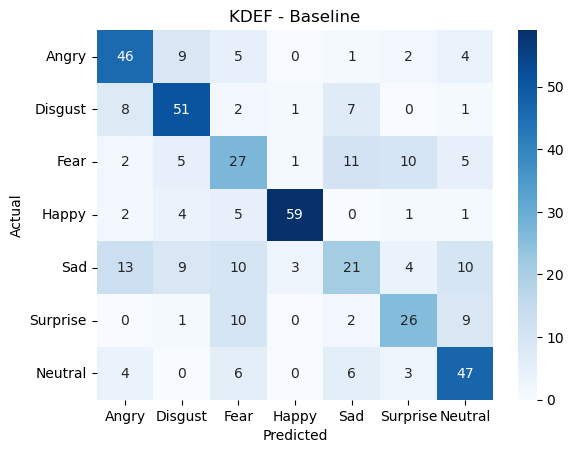

Training: Class weights


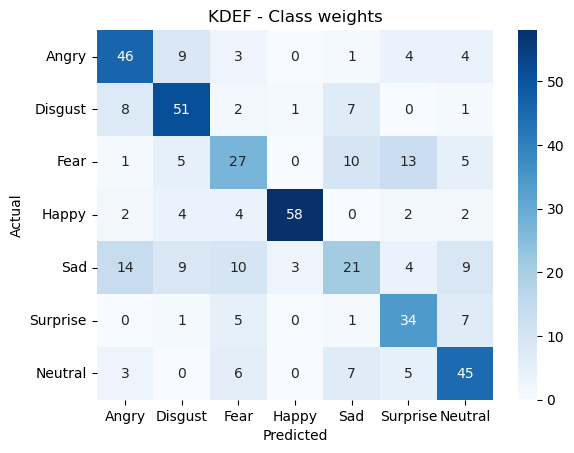

Training: Tune C


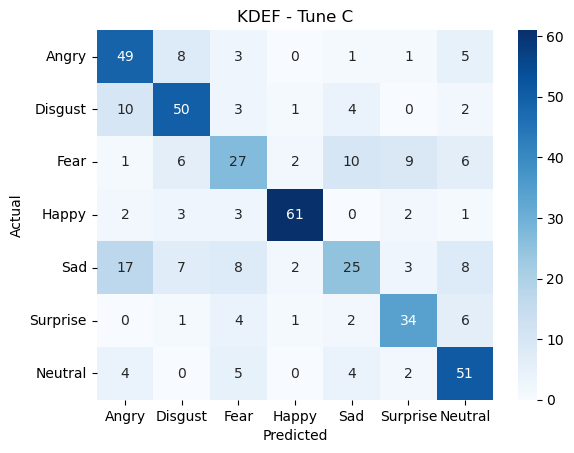

Training: Both changes


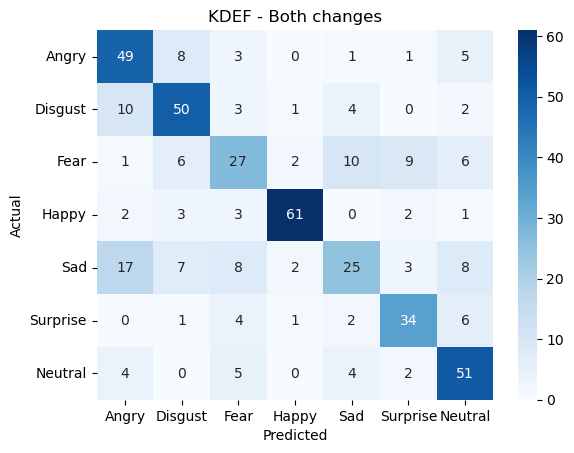

In [71]:
#Train four variations of the SVM model on KDEF HOG features to test improvements
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Test two possible improvements separately and together
variations = [
    ("Baseline", None, 1.0),
    ("Class weights", "balanced", 1.0),
    ("Tune C", None, 3.0),
    ("Both changes", "balanced", 3.0)
]

creative_results = []
creative_models = {}

for name, weights, c in variations:
    print("Training:", name)

    model = make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=c,
            class_weight=weights,
            random_state=42
        )
    )

    model.fit(X_train_hog, y_train)
    predictions = model.predict(X_val_hog)

    result = evaluate(
        y_val,
        predictions,
        "KDEF - " + name
    )

    result["change"] = name
    creative_results.append(result)
    creative_models[name] = model

In [72]:
#Compare results of the four variations
creative_table = pd.DataFrame(creative_results)

display(
    creative_table[
        ["change", "acc", "bal_acc", "macro_f1"]
    ].round(3)
)

,change,acc,bal_acc,macro_f1
0,Baseline,0.610,0.604,0.599
1,Class weights,0.621,0.622,0.612
2,Tune C,0.654,0.653,0.645
3,Both changes,0.654,0.653,0.645


In [75]:
#Select and save
import joblib

# Find the best validation result
best_row = creative_table.loc[
    creative_table["macro_f1"].idxmax()
]

best_name = best_row["change"]
best_creative_b = creative_models[best_name]

print("Best variation:", best_name)
print("Macro F1:", round(best_row["macro_f1"], 3))

# Save the selected model
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": best_creative_b,
        "feature": "HOG",
        "labels": EMOTIONS
    },
    models_dir / "kdef_creative_best.pkl"
)

print("Model saved!")

Best variation: Tune C
Macro F1: 0.645
Model saved!


### Creative Challenge Results

For the creative challenge, I tested two changes to the HOG + SVM model: adding balanced class weights and changing the C parameter.

The best result came from changing C from 1.0 to 3.0. This improved the validation macro F1 score from 0.599 to 0.645.

This suggests that changing the regularization parameter helped the model recognize the different emotions more accurately.

I selected this variation as the best model and saved it for future use.

In [76]:
saved = joblib.load(models_dir / "kdef_creative_best.pkl")

print("Feature:", saved["feature"])
print("Model:", saved["model"])

predictions = saved["model"].predict(X_val_hog[:5])
print("Predictions:", predictions)

Feature: HOG
Model: Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(C=3.0, random_state=42))])
Predictions: [5 5 2 0 0]


### Creative Challenge — Ablation Study

I tested two changes to the HOG + SVM model: using balanced class weights and increasing C from 1.0 to 3.0.

Adding class weights slightly improved the macro F1 score from 0.599 to 0.612. Changing C gave a larger improvement, reaching 0.645.

Combining both changes gave the same results as tuning C alone, so adding class weights did not provide any additional improvement in this case.

Based on these results, I selected HOG + SVM with C = 3.0 as the best model.

Incorrect predictions: 157


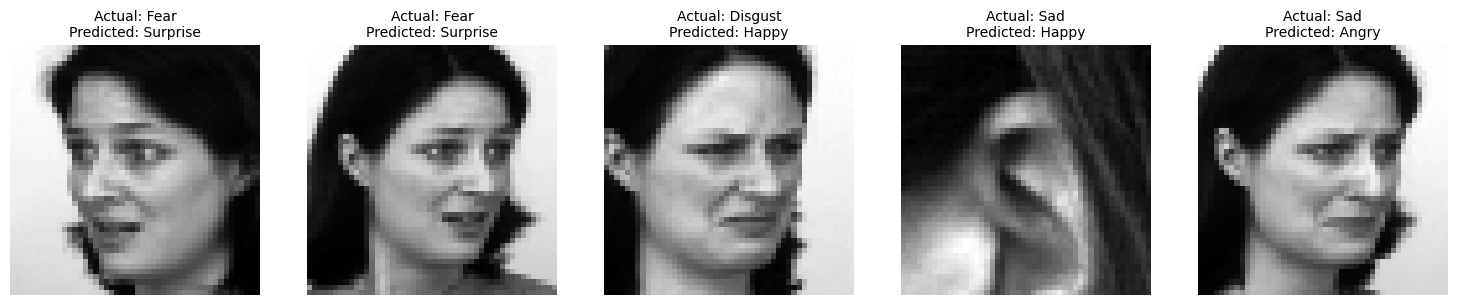

In [78]:
import numpy as np
import matplotlib.pyplot as plt

# Predictions on the validation set
val_pred = best_creative_b.predict(X_val_hog)

# Find incorrectly classified images
wrong_indices = np.where(y_val != val_pred)[0]

print("Incorrect predictions:", len(wrong_indices))

# Display five mistakes
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

for ax, idx in zip(axes, wrong_indices[:5]):
    ax.imshow(X_val_img[idx], cmap="gray")
    ax.set_title(
        f"Actual: {EMOTIONS[y_val[idx]]}\n"
        f"Predicted: {EMOTIONS[val_pred[idx]]}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [79]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, val_pred, labels=range(7))

# Remove correct predictions
np.fill_diagonal(cm, 0)

mistakes = []

for actual in range(7):
    for predicted in range(7):
        if actual != predicted:
            mistakes.append((
                EMOTIONS[actual],
                EMOTIONS[predicted],
                cm[actual, predicted]
            ))

mistakes.sort(key=lambda x: x[2], reverse=True)

print("Most common mistakes:")

for actual, predicted, count in mistakes[:5]:
    print(f"{actual} predicted as {predicted}: {count} images")

Most common mistakes:
Sad predicted as Angry: 17 images
Disgust predicted as Angry: 10 images
Fear predicted as Sad: 10 images
Fear predicted as Surprise: 9 images
Angry predicted as Disgust: 8 images


### Error Analysis

I looked at some incorrectly classified images to understand where the model makes mistakes.

The most common mistake was predicting Sad as Angry (17 images). The model also confused Disgust with Angry (10 images) and Fear with Sad (10 images).

These mistakes might happen because some facial expressions share similar features. For example, Fear and Surprise can both involve raised eyebrows and an open mouth, making them difficult to distinguish.

Overall, the model performs reasonably well, but it still struggles with some emotions.